# Chapter 33: Convolution

Checks [chapter 33](../../book/33-convolution.md). The model is the **one-dimensional convolution layer** of the
chapter: `output[position] = sum(kernel[j] * signal[position + j] for j in range(kernel_width))`, with the same kernel at
every position, applied to NumPy arrays in float64 and seeded. Stride and upsampling are checked on a smooth function
(a sine) read at every second position. These are measurements, not proofs: the proofs are in `Convolution.lean`. Run
every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
import matplotlib.pyplot as plt
from common import use_style, save_figure, report as report_check, NEAREST, VERTICAL, BOUND, MODEL, BEFORE

use_style()
SEED = 33
COUNTS = {"could fail and passed": 0, "by construction": 0}


def report(label, passed, detail=""):
    """A check that could fail. It stops the notebook if it does, and is counted if it passes."""
    report_check(label, passed, detail)
    COUNTS["could fail and passed"] += 1


def note_by_construction(text, tag="by construction, cannot fail"):
    """A line that holds because of how the code is written. It is not evidence and is not counted as a pass."""
    COUNTS["by construction"] += 1
    print(f"[{tag}] " + text)


def apply_convolution(kernel, signal):
    """APPLY_CONVOLUTION at every position that has the whole kernel under it."""
    kernel_width = len(kernel)
    position_count = len(signal) - kernel_width + 1
    return sum(kernel[offset] * signal[offset:offset + position_count] for offset in range(kernel_width))


def get_kernel_size(kernel):
    return float(np.abs(kernel).sum())


def apply_position_dependent_layer(kernel, signal):
    """Control: the same sum, but the weights are scaled by a number that depends on the position. Not a convolution."""
    positions = np.arange(len(signal) - len(kernel) + 1)
    scale = 1.0 + 0.8 * np.sin(0.7 * positions) + 0.01 * positions
    return scale * apply_convolution(kernel, signal)

## Claim 1: the example by hand

Kernel `1, -2, 1`, summed sizes 4. The signal `5, 5, 5` gives 0, the signal `5.1, 4.9, 5.1` gives 0.4, and the bound
`4 * 0.1 = 0.4` is reached. Predicted: the two outputs are 0 and 0.4 (to rounding), the gap equals the bound to 1e-12.
The claim fails if the gap is larger than the bound or if the arithmetic differs from 0 and 0.4.

In [2]:
hand_kernel = np.array([1.0, -2.0, 1.0])
hand_output = float(apply_convolution(hand_kernel, np.array([5.0, 5.0, 5.0]))[0])
hand_other_output = float(apply_convolution(hand_kernel, np.array([5.1, 4.9, 5.1]))[0])
hand_gap = abs(hand_output - hand_other_output)
hand_limit = get_kernel_size(hand_kernel) * 0.1
report("kernel 1, -2, 1: outputs 0 and 0.4, and the gap reaches the bound 0.4",
       abs(hand_output) < 1e-12 and abs(hand_other_output - 0.4) < 1e-12 and abs(hand_gap - hand_limit) < 1e-12,
       f"outputs {hand_output:.6f} and {hand_other_output:.6f}, gap {hand_gap:.6f}, bound {hand_limit:.6f}")

[PASS] kernel 1, -2, 1: outputs 0 and 0.4, and the gap reaches the bound 0.4  (outputs 0.000000 and 0.400000, gap 0.400000, bound 0.400000)


## Claim 2: no steeper than the summed kernel, whatever the length (`convolution_slope_is_at_most_summed_kernel`)

For 200 random kernels (width 1 to 9, weights from a standard normal), and signal lengths 10, 1000 and 100 000, draw a
signal and a second signal that differs from it by at most `max_gap = 0.1` at every position (the gap is uniform in
`[-0.1, 0.1]`). Predicted: every output gap is at most `kernel_size * 0.1`, at every length. The claim fails if any
output gap exceeds the bound.

**Tightness.** Choose the gap `max_gap * sign(kernel[j])` under the kernel at one position: predicted that the output
gap equals the bound (the check-yourself kernel `0.5, 0.5, -1` with gap 2 should give 4). It fails if the bound is not
reached, which would mean the factor is not the right one.

**Adversarial search.** Random gaps almost never come near the bound for a wide kernel (only width 1 gets close),
so the check above is weak for wide kernels. For each width 1 to 9, 20 random kernels (their own seeded generator),
a signal of length 40 and a start gap of `max_gap` times random signs, 300 steps of coordinate search (set one gap to
`+max_gap` or `-max_gap`, keep it if the largest output gap rises). Predicted: no ratio above 1. It fails if any
ratio exceeds 1 (beyond 1e-9).

**Control (the hypothesis broken: not a convolution).** The same sum with weights scaled by a position-dependent number
(up to about 1 + 0.8 + 0.01 * position), with the gap lined up with the kernel signs everywhere. Predicted: its output
gap exceeds the kernel-size bound, and by more on a longer signal, which is the length entering. It fails to be a
control if it never exceeds the bound. Its ratio is the control's own scale factor at the chosen position
(`scale[best_position]`), not a measurement of anything else.

In [3]:
generator = np.random.default_rng(SEED)
MAX_GAP = 0.1
worst_ratio_by_length = {}
worst_random_ratio_by_width = {}
for signal_length in (10, 1000, 100_000):
    worst_ratio = 0.0
    for trial in range(200):
        kernel_width = int(generator.integers(1, 10))
        kernel = generator.standard_normal(kernel_width)
        signal = generator.standard_normal(signal_length)
        other_signal = signal + generator.uniform(-MAX_GAP, MAX_GAP, signal_length)
        output_gap = np.abs(apply_convolution(kernel, signal) - apply_convolution(kernel, other_signal)).max()
        worst_ratio = max(worst_ratio, float(output_gap) / (get_kernel_size(kernel) * MAX_GAP))
        worst_random_ratio_by_width[kernel_width] = max(worst_random_ratio_by_width.get(kernel_width, 0.0),
                                                        float(output_gap) / (get_kernel_size(kernel) * MAX_GAP))
    worst_ratio_by_length[signal_length] = worst_ratio
report("every output gap is at most kernel_size * max_gap, at lengths 10, 1000 and 100 000",
       all(ratio <= 1.0 for ratio in worst_ratio_by_length.values()),
       "largest output gap over bound: " + ", ".join(f"{length}: {ratio:.3f}" for length, ratio in worst_ratio_by_length.items()))

print("random gaps, largest output gap over bound by kernel width: "
      + ", ".join(f"{width}: {worst_random_ratio_by_width[width]:.3f}" for width in sorted(worst_random_ratio_by_width)))

SEARCH_STEPS = 300
SEARCH_LENGTH = 40
search_generator = np.random.default_rng(SEED + 100)
worst_search_ratio_by_width = {}
for kernel_width in range(1, 10):
    worst_search_ratio = 0.0
    for trial in range(20):
        kernel = search_generator.standard_normal(kernel_width)
        signal = search_generator.standard_normal(SEARCH_LENGTH)
        gap = MAX_GAP * search_generator.choice([-1.0, 1.0], SEARCH_LENGTH)
        get_gap = lambda gap_values: float(np.abs(apply_convolution(kernel, signal)
                                                  - apply_convolution(kernel, signal + gap_values)).max())
        best_gap = get_gap(gap)
        for step in range(SEARCH_STEPS):
            index = int(search_generator.integers(0, SEARCH_LENGTH))
            trial_gap = gap.copy()
            trial_gap[index] = MAX_GAP * search_generator.choice([-1.0, 1.0])
            trial_value = get_gap(trial_gap)
            if trial_value > best_gap:
                gap, best_gap = trial_gap, trial_value
        worst_search_ratio = max(worst_search_ratio, best_gap / (get_kernel_size(kernel) * MAX_GAP))
    worst_search_ratio_by_width[kernel_width] = worst_search_ratio
report("adversarial search: no output gap exceeds kernel_size * max_gap, for kernel widths 1 to 9",
       all(ratio <= 1.0 + 1e-9 for ratio in worst_search_ratio_by_width.values()),
       "largest output gap over bound by width: " + ", ".join(f"{width}: {ratio:.3f}" for width, ratio in worst_search_ratio_by_width.items()))

check_kernel = np.array([0.5, 0.5, -1.0])
check_signal = generator.standard_normal(20)
check_other_signal = check_signal.copy()
check_other_signal[4:7] += 2.0 * np.sign(check_kernel)        # the gap lines up with the kernel signs at position 4
tight_gap = abs(float(apply_convolution(check_kernel, check_signal)[4] - apply_convolution(check_kernel, check_other_signal)[4]))
report("kernel 0.5, 0.5, -1 with gap 2: the output gap reaches 2 * 2 = 4",
       abs(tight_gap - 4.0) < 1e-12, f"output gap {tight_gap:.6f}, bound {get_kernel_size(check_kernel) * 2.0:.6f}")

control_kernel = np.array([1.0, -2.0, 1.0])
control_ratio_by_length = {}
for signal_length in (10, 1000, 100_000):
    signal = generator.standard_normal(signal_length)
    other_signal = signal.copy()
    position_count = signal_length - len(control_kernel) + 1
    # Raise the signal by MAX_GAP * sign(kernel) under the kernel at the position where the scale is largest.
    scale = 1.0 + 0.8 * np.sin(0.7 * np.arange(position_count)) + 0.01 * np.arange(position_count)
    best_position = int(np.argmax(scale))
    other_signal[best_position:best_position + 3] += MAX_GAP * np.sign(control_kernel)
    control_gap = abs(float(apply_position_dependent_layer(control_kernel, signal)[best_position]
                            - apply_position_dependent_layer(control_kernel, other_signal)[best_position]))
    control_ratio_by_length[signal_length] = control_gap / (get_kernel_size(control_kernel) * MAX_GAP)
print("the control's ratios are its own scale factor at the chosen position, scale[best_position]; they are not measured from a model")
report("control: the position-dependent layer breaks the bound, more on a longer signal (ratio = the control's own scale factor)",
       control_ratio_by_length[10] > 1.0 and control_ratio_by_length[100_000] > control_ratio_by_length[10],
       "output gap over bound (the control's own scale factor): " + ", ".join(f"{length}: {ratio:.2f}" for length, ratio in control_ratio_by_length.items()))

[PASS] every output gap is at most kernel_size * max_gap, at lengths 10, 1000 and 100 000  (largest output gap over bound: 10: 0.997, 1000: 1.000, 100000: 1.000)
random gaps, largest output gap over bound by kernel width: 1: 1.000, 2: 1.000, 3: 0.994, 4: 0.982, 5: 0.971, 6: 0.957, 7: 0.944, 8: 0.890, 9: 0.904


[PASS] adversarial search: no output gap exceeds kernel_size * max_gap, for kernel widths 1 to 9  (largest output gap over bound by width: 1: 1.000, 2: 1.000, 3: 1.000, 4: 1.000, 5: 1.000, 6: 1.000, 7: 1.000, 8: 1.000, 9: 1.000)
[PASS] kernel 0.5, 0.5, -1 with gap 2: the output gap reaches 2 * 2 = 4  (output gap 4.000000, bound 4.000000)
the control's ratios are its own scale factor at the chosen position, scale[best_position]; they are not measured from a model
[PASS] control: the position-dependent layer breaks the bound, more on a longer signal (ratio = the control's own scale factor)  (output gap over bound (the control's own scale factor): 10: 1.81, 1000: 11.67, 100000: 1001.73)


## Claim 3: locality (`convolution_reads_only_under_its_kernel`, `convolution_stack_reads_only_its_window`)

An output reads `kernel_width` inputs. Take one output position and change the input at one position by 1, at every
distance in turn, for 1, 2 and 3 layers of a width-3 kernel with every weight non-zero. Predicted: the output changes
only when the changed input is under the layer stack, and the change is exactly 0 (not just small) beyond. The theorem
allows `layer_count * kernel_width` positions (3, 6, 9); the exact reach of a stack is
`layer_count * (kernel_width - 1) + 1` (3, 5, 7), inside what the theorem allows. "Exactly 0 beyond the window" is forced by the array indexing (an output reads only the entries under it), so it is
printed as by construction and not counted. The checks that could fail are: every change inside the exact reach is
above 0 (otherwise the check cannot see anything), and the measured reach is exactly 3, 5, 7.

The same check with a ReLU between layers is made as well; the chapter's claim covers convolutions only, so that is an extra.

In [4]:
KERNEL_WIDTH = 3
OUTPUT_POSITION = 0
LAYER_COUNTS = (1, 2, 3)
generator = np.random.default_rng(SEED + 1)
layer_kernels = [generator.uniform(0.5, 1.5, KERNEL_WIDTH) * generator.choice([-1.0, 1.0], KERNEL_WIDTH) for layer in range(3)]
base_signal = generator.standard_normal(40)


def measure_change_by_distance(layer_count, between_layers=None):
    """Output change at OUTPUT_POSITION when the input at OUTPUT_POSITION + distance is raised by 1."""
    def run(signal):
        for kernel in layer_kernels[:layer_count]:
            signal = apply_convolution(kernel, signal)
            if between_layers is not None:
                signal = between_layers(signal)
        return signal
    base_output = run(base_signal)[OUTPUT_POSITION]
    changes = []
    for distance in range(0, 14):
        changed_signal = base_signal.copy()
        changed_signal[OUTPUT_POSITION + distance] += 1.0
        changes.append(abs(float(run(changed_signal)[OUTPUT_POSITION] - base_output)))
    return np.array(changes)


change_by_layers = {layer_count: measure_change_by_distance(layer_count) for layer_count in LAYER_COUNTS}
relu_change_by_layers = {layer_count: measure_change_by_distance(layer_count, lambda values: np.maximum(values, 0.0))
                         for layer_count in LAYER_COUNTS}
window_rows = []
for layer_count in LAYER_COUNTS:
    allowed_window = layer_count * KERNEL_WIDTH
    exact_reach = layer_count * (KERNEL_WIDTH - 1) + 1
    changes = change_by_layers[layer_count]
    window_rows.append((layer_count, allowed_window, exact_reach, float(changes[allowed_window:].max()),
                        float(changes[:exact_reach].min()), float(relu_change_by_layers[layer_count][allowed_window:].max())))
assert all(row[3] == 0.0 and row[5] == 0.0 for row in window_rows)
note_by_construction("changes beyond layer_count * kernel_width leave the output exactly unchanged, also with a ReLU: "
                     + "; ".join(f"{row[0]} layers: largest change beyond {row[3]:.1f}, with ReLU {row[5]:.1f}" for row in window_rows))
report("every change within the exact reach moves the output",
       all(row[4] > 0.0 for row in window_rows),
       "; ".join(f"{row[0]} layers: exact reach {row[2]}, smallest change within reach {row[4]:.3f}" for row in window_rows))
measured_reach = [int(np.nonzero(change_by_layers[layer_count])[0].max()) + 1 for layer_count in LAYER_COUNTS]
report("the farthest input that matters is at exactly layer_count * (kernel_width - 1) + 1 positions",
       measured_reach == [3, 5, 7], f"measured reach {measured_reach}")

[by construction, cannot fail] changes beyond layer_count * kernel_width leave the output exactly unchanged, also with a ReLU: 1 layers: largest change beyond 0.0, with ReLU 0.0; 2 layers: largest change beyond 0.0, with ReLU 0.0; 3 layers: largest change beyond 0.0, with ReLU 0.0
[PASS] every change within the exact reach moves the output  (1 layers: exact reach 3, smallest change within reach 0.504; 2 layers: exact reach 5, smallest change within reach 0.649; 3 layers: exact reach 7, smallest change within reach 0.128)
[PASS] the farthest input that matters is at exactly layer_count * (kernel_width - 1) + 1 positions  (measured reach [3, 5, 7])


## Claim 4: the same weights at every position (a convolution commutes with a shift)

This is the content of "a pattern means the same wherever it appears", and the first figure draws it. Shift a signal by
5 positions. Predicted: the convolution of the shifted signal is the shifted convolution, to rounding (below 1e-12).
The control is the position-dependent layer of claim 2, which is not a convolution: predicted that the difference is of
the size of the outputs themselves (more than a tenth of the largest output). It fails if the convolution differs from
the shifted output by more than 1e-12 or if the control agrees with it.

In [5]:
SHIFT = 5
SIGNAL_LENGTH = 60
smooth_kernel = np.array([0.3, 0.9, -0.5, 0.2])
bump_positions = np.arange(SIGNAL_LENGTH)
bump_signal = np.exp(-0.5 * ((bump_positions - 18) / 3.0) ** 2) + 0.5 * np.exp(-0.5 * ((bump_positions - 30) / 1.5) ** 2)
shifted_signal = np.roll(bump_signal, SHIFT)           # the signal is nearly zero at both ends, so nothing wraps round

convolution_output = apply_convolution(smooth_kernel, bump_signal)
convolution_output_of_shifted = apply_convolution(smooth_kernel, shifted_signal)
shifted_convolution_output = np.roll(convolution_output, SHIFT)
interior = slice(SHIFT, None)                           # leave out the first positions, where the roll wraps
convolution_error = float(np.abs(convolution_output_of_shifted[interior] - shifted_convolution_output[interior]).max())

control_output = apply_position_dependent_layer(smooth_kernel, bump_signal)
control_output_of_shifted = apply_position_dependent_layer(smooth_kernel, shifted_signal)
shifted_control_output = np.roll(control_output, SHIFT)
control_error = float(np.abs(control_output_of_shifted[interior] - shifted_control_output[interior]).max())
output_scale = float(np.abs(convolution_output).max())
report("a convolution commutes with a shift; the position-dependent control does not",
       convolution_error < 1e-12 and control_error > 0.1 * output_scale,
       f"convolution: largest difference {convolution_error:.2e}; control: {control_error:.3f}, "
       f"against output scale {output_scale:.3f}")

[PASS] a convolution commutes with a shift; the position-dependent control does not  (convolution: largest difference 0.00e+00; control: 1.179, against output scale 0.872)


wrote book/figures/33-shift-commutes-with-convolution.png


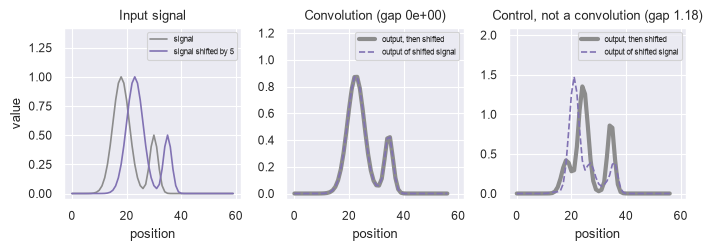

In [6]:
figure, axes = plt.subplots(1, 3, figsize=(7.0, 2.6), sharex=True)
axes[0].plot(bump_positions, bump_signal, color=BEFORE, label="signal")
axes[0].plot(bump_positions, shifted_signal, color=MODEL, label=f"signal shifted by {SHIFT}")
axes[0].set_title("Input signal")
output_positions = np.arange(len(convolution_output))
axes[1].plot(output_positions, shifted_convolution_output, color=BEFORE, linewidth=3.0, label="output, then shifted")
axes[1].plot(output_positions, convolution_output_of_shifted, color=MODEL, linestyle="--", label="output of shifted signal")
axes[1].set_title(f"Convolution (gap {convolution_error:.0e})")
axes[2].plot(output_positions, shifted_control_output, color=BEFORE, linewidth=3.0, label="output, then shifted")
axes[2].plot(output_positions, control_output_of_shifted, color=MODEL, linestyle="--", label="output of shifted signal")
axes[2].set_title(f"Control, not a convolution (gap {control_error:.2f})")
for axis in axes:
    axis.set_xlabel("position")
    axis.set_ylim(top=axis.get_ylim()[1] * 1.35)         # room for the legend above the curves
    axis.legend(fontsize=6, loc="upper right")
axes[0].set_ylabel("value")
figure.tight_layout()
save_figure(figure, "33-shift-commutes-with-convolution")
plt.show()

## Claim 5: what a window cannot see, as a figure

The second figure draws claim 3: the output change against how far from the output the input was changed, for 1, 2 and 3
layers, with the theorem's window `layer_count * kernel_width` drawn as a green line. Every number is the one measured above.

wrote book/figures/33-output-change-against-distance.png


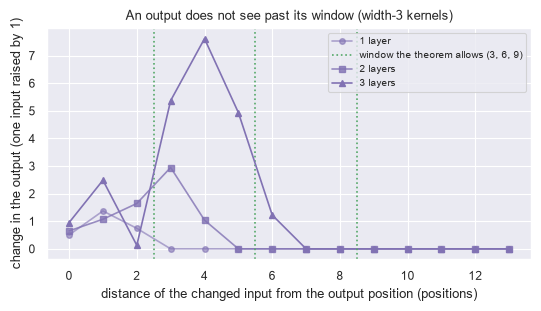

In [7]:
figure, axis = plt.subplots(figsize=(5.5, 3.2))
markers = {1: "o", 2: "s", 3: "^"}
for layer_count in LAYER_COUNTS:
    axis.plot(np.arange(len(change_by_layers[layer_count])), change_by_layers[layer_count], marker=markers[layer_count],
              color=MODEL, alpha=0.4 + 0.2 * layer_count, markersize=4, label=f"{layer_count} layer" + ("s" if layer_count > 1 else ""))
    axis.axvline(layer_count * KERNEL_WIDTH - 0.5, color=BOUND, linestyle=":", linewidth=1.2,
                 label="window the theorem allows (3, 6, 9)" if layer_count == 1 else None)
axis.set_xlabel("distance of the changed input from the output position (positions)")
axis.set_ylabel("change in the output (one input raised by 1)")
axis.set_title("An output does not see past its window (width-3 kernels)")
axis.legend(fontsize=7)
figure.tight_layout()
save_figure(figure, "33-output-change-against-distance")
plt.show()

## Claim 6: stride doubles the slope (`stride_is_squeezing`, `stride_doubles_the_slope`)

Take `model(x) = sin(3x)`, slope limit 3. The strided model `model(2x)` is the squeezed model by definition, so that identity is printed as "by construction, cannot fail" and not counted. Predicted: its steepest measured slope is 6, so
that the bound `2 * 3` is reached and never exceeded. Moving the input by 0.1 moves the output by at most `6 * 0.1 = 0.6`.
Two strides in a row from slope 1.5 (model `sin(1.5x)`) should give a measured slope at most 6 and close to it. This is one
hand-picked function: the slope of `sin(6x)` is read, and the discrete strided convolution layer itself is not run. The
line is labelled "from the formula, one sine" and is not counted. The notebook still stops if a measured slope exceeds `2 * slope_limit` (beyond rounding of 1e-9) or falls well short of it (under 0.99 times
it), which would mean the stated factor of two is the wrong one.

**Upsampling.** `upsample(model) = model(x / 2)`; a stride of two after it gives the model back by the same algebra, so it is also printed as by construction and not counted.

In [8]:
GRID = np.linspace(-5.0, 5.0, 20001)
GRID_STEP = float(GRID[1] - GRID[0])


def get_measured_slope(function):
    return float(np.abs(np.diff(function(GRID))).max() / GRID_STEP)


def stride(function):
    return lambda inputs: function(2.0 * inputs)


def compress(factor, function):
    """COMPRESS factor model: the same function squeezed sideways by factor."""
    return lambda inputs: function(factor * inputs)


def upsample(function):
    return lambda inputs: function(inputs / 2.0)


model_slope_three = lambda inputs: np.sin(3.0 * inputs)
strided_model = stride(model_slope_three)
squeezed_model = compress(2.0, model_slope_three)
definitions_gap = float(np.abs(strided_model(GRID) - squeezed_model(GRID)).max())
slope_before = get_measured_slope(model_slope_three)
slope_after = get_measured_slope(strided_model)
step_move = float(np.abs(strided_model(GRID + 0.1) - strided_model(GRID)).max())
model_slope_one_and_half = lambda inputs: np.sin(1.5 * inputs)
slope_one_and_half = get_measured_slope(model_slope_one_and_half)
slope_two_strides = get_measured_slope(stride(stride(model_slope_one_and_half)))
roundtrip_gap = float(np.abs(stride(upsample(model_slope_three))(GRID) - model_slope_three(GRID)).max())
note_by_construction(f"stride and COMPRESS 2 are the same lambda (difference {definitions_gap:.1e}); "
                     f"stride after upsampling is model(2 * (x / 2)) (difference {roundtrip_gap:.1e}). Not counted as evidence.")
assert (0.99 * 6.0 <= slope_after <= 6.0 + 1e-9
        and step_move <= 0.6 + 1e-9
        and 0.99 * 6.0 <= slope_two_strides <= 6.0 + 1e-9)
note_by_construction(
       f"the slope limit doubles under stride on one sine, sin(3x) read at 2x; the strided layer itself was not run (3 to 6; 1.5 to 6 after two strides): "
       f"slope {slope_before:.4f} -> {slope_after:.4f}; "
       f"move for input step 0.1 is {step_move:.4f} (bound 0.6); {slope_one_and_half:.4f} -> {slope_two_strides:.4f} after two strides",
       tag="from the formula, one sine, not counted")

[by construction, cannot fail] stride and COMPRESS 2 are the same lambda (difference 0.0e+00); stride after upsampling is model(2 * (x / 2)) (difference 0.0e+00). Not counted as evidence.
[from the formula, one sine, not counted] the slope limit doubles under stride on one sine, sin(3x) read at 2x; the strided layer itself was not run (3 to 6; 1.5 to 6 after two strides): slope 3.0000 -> 6.0000; move for input step 0.1 is 0.5910 (bound 0.6); 1.5000 -> 6.0000 after two strides


In [9]:
print(f"checks that could fail and passed: {COUNTS['could fail and passed']}; printed as by construction or from the formula, not counted: {COUNTS['by construction']}")


checks that could fail and passed: 8; printed as by construction or from the formula, not counted: 3
